[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_RQI_Mosaic_SpatialBias_DualPol/blob/main/notebooks/02_dem_beam_blockage_rqi.ipynb)

# 02 · DEM, การบังลำคลื่นจากภูมิประเทศ และดัชนีคุณภาพเรดาร์ (RQI)
*DEM mosaicking, beam propagation, beam blockage and the radar quality index*

| | |
|---|---|
| **ระดับ** | 🟢 ป.ตรี ปี 3–4 และ 🔵 ป.โท |
| **เวลาโดยประมาณ** | 90–120 นาที |
| **ควรผ่านมาก่อน** | 00 |
| **ข้อมูลเข้า** | DEM SRTM 4 แผ่น (250 ม.), ตำแหน่งและมุมยกของเรดาร์ 5 สถานี |
| **ผลลัพธ์** | DEM โมเสค, แผนที่ CBB, แผนที่ RQI ของเครือข่าย, ตาราง RQI รายลุ่มน้ำ |

> 📌 **วิธีใช้:** กด *Runtime ▸ Run all* ได้ทันที หรือรันทีละเซลล์ (Shift+Enter) พร้อมอ่านคำอธิบาย
> เซลล์ที่มีหัวข้อ 🔑 เป็นเฉลยที่ซ่อนไว้ ลองทำแบบฝึกหัดก่อนแล้วค่อยเปิดดู

## 🎯 วัตถุประสงค์การเรียนรู้
1. **โมเสค** DEM หลายแผ่นให้เป็นแผ่นเดียว ตัดตามพื้นที่ศึกษา และสร้าง hillshade
2. **คำนวณ** ความสูงของลำคลื่นเรดาร์ตามระยะด้วยแบบจำลองรัศมีโลกประสิทธิผล 4/3
3. **คำนวณ** สัดส่วนลำคลื่นที่ถูกภูมิประเทศบัง (PBB/CBB) ตามสมการของ Bech et al. (2003)
4. **สร้าง** ดัชนีคุณภาพเรดาร์ (RQI) จากการบังและความสูงของลำคลื่น และเลือกเรดาร์ที่ดีที่สุดในแต่ละพิกเซล
5. **วิเคราะห์** คุณภาพการสังเกตฝนรายลุ่มน้ำด้วยสถิติเชิงพื้นที่ (zonal statistics)

## 1. หลักการ
### 1.1 ลำคลื่นเรดาร์เดินทางอย่างไร
คลื่นไมโครเวฟหักเหในบรรยากาศ (ดัชนีหักเหลดลงตามความสูง) จึงโค้งลงเล็กน้อย แต่โค้งน้อยกว่าผิวโลก
เราแทนผลนี้ด้วย "โลกที่ใหญ่ขึ้น" รัศมี $k_e a$ โดย $k_e = 4/3$ ในบรรยากาศมาตรฐาน (Doviak & Zrnić 1993)

$$h(r,\theta) = \sqrt{r^2 + (k_e a)^2 + 2 r\,k_e a \sin\theta} \; - \; k_e a \; + \; h_0$$

ความกว้างลำคลื่นครึ่งกำลัง (half-power beamwidth) $\theta_{3dB} \approx 1^\circ$ ทำให้รัศมีลำคลื่นโตตามระยะ
$w(r) = r\tan(\theta_{3dB}/2)$ → ที่ 100 กม. ลำคลื่นหนาเกือบ 1.75 กม.

### 1.2 การบังลำคลื่น (beam blockage)
ให้ $y$ = ความสูงภูมิประเทศ − ความสูงศูนย์กลางลำคลื่น และ $a = y / w$ สัดส่วนพื้นที่หน้าตัดวงกลมที่ถูกบัง (partial beam blockage):

$$\text{PBB} = \frac{a\sqrt{1-a^2} + \arcsin a + \pi/2}{\pi}, \qquad -1 \le a \le 1$$

สิ่งที่ถูกบังแล้วย่อมถูกบังต่อไปทั้ง ray จึงใช้ **CBB** = ค่าสูงสุดสะสมของ PBB ตามระยะ

### 1.3 ดัชนีคุณภาพเรดาร์ (Radar Quality Index, RQI)
ระบบ MRMS ของสหรัฐฯ (Zhang et al. 2012) ให้คะแนนคุณภาพ 0–1 ทุกพิกเซลจากสองปัจจัย

$$\text{RQI} = \text{RQI}_{blk}\times\text{RQI}_{hgt}$$
$$\text{RQI}_{blk} = \begin{cases}1 & \text{CBB} \le 0.1\\ \dfrac{0.5-\text{CBB}}{0.4} & 0.1<\text{CBB}<0.5 \\ 0 & \text{CBB}\ge 0.5\end{cases}
\qquad
\text{RQI}_{hgt} = \exp\!\left[-\left(\frac{\max(0,\,h_{AGL}-1\,\text{km})}{1.5\,\text{km}}\right)^2\right]$$

ยิ่งลำคลื่นสูงจากพื้น ยิ่งวัดฝนที่ระดับพื้นได้แย่ลง (ฝนอาจระเหย/โตขึ้นใต้ลำคลื่น หรือลำคลื่นเข้าชั้นหลอมเหลว)

In [1]:
PACKAGES = ('teaching_data', 'products')
#@title ⚙️ เตรียมสภาพแวดล้อม (รันเซลล์นี้ก่อนทุกครั้ง) { display-mode: "form" }
import os, sys, subprocess
REPO, OWNER = "Teach_RQI_Mosaic_SpatialBias_DualPol", "nattaponm"
if "google.colab" in sys.modules:
    if not os.path.exists(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        f"https://github.com/{OWNER}/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
else:  # running on your own computer: move to the repository root
    while not os.path.exists("config/study_area.yaml") and os.getcwd() != os.path.dirname(os.getcwd()):
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
from radteach import colab
P = colab.setup(packages=PACKAGES)

installing: arm_pyart (about 1–2 minutes the first time) …
downloading teaching_data_v1.zip …
teaching_data_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
downloading teaching_products_v1.zip …
teaching_products_v1.zip ready in /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw
repository : /content/Teach_RQI_Mosaic_SpatialBias_DualPol
Colab      : True
Thai font  : Sarabun
data       : /content/Teach_RQI_Mosaic_SpatialBias_DualPol/data/raw


## 2. โมเสค DEM
DEM ชุดนี้คือ SRTM ที่ลดความละเอียดเป็น ~250 ม. แบ่งเป็นแผ่นละ 5°×5° (ชื่อ `srtm_XX_YY` ตามระบบของ CGIAR-CSI)

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, rasterio
from radteach import dem, geometry as geo, rqi as RQ, mosaic, io, config, plotting as pl, mapping as mp
cfg = config.load_all()
tiles = sorted(P.dem.glob("*.tif"))
rows = []
for t in tiles:
    with rasterio.open(t) as s:
        rows.append(dict(tile=t.name, left=s.bounds.left, right=s.bounds.right, bottom=s.bounds.bottom, top=s.bounds.top,
                         res_deg=round(s.res[0], 5), width=s.width, height=s.height, crs=str(s.crs)))
pd.DataFrame(rows)

,tile,left,right,bottom,top,res_deg,width,height,crs
0,srtm_56_08_250m.tif,94.999583,100.000417,19.999584,25.000417,0.0025,2000,2000,EPSG:4326
1,srtm_56_09_250m.tif,94.999583,100.000417,14.999584,20.000417,0.0025,2000,2000,EPSG:4326
2,srtm_57_08_250m.tif,99.999584,105.000417,19.999584,25.000417,0.0025,2000,2000,EPSG:4326
3,srtm_57_09_250m.tif,99.999584,105.000417,14.999584,20.000417,0.0025,2000,2000,EPSG:4326


DEM โมเสค: 2200 × 2360 พิกเซล, ความสูง -9–2576 ม.


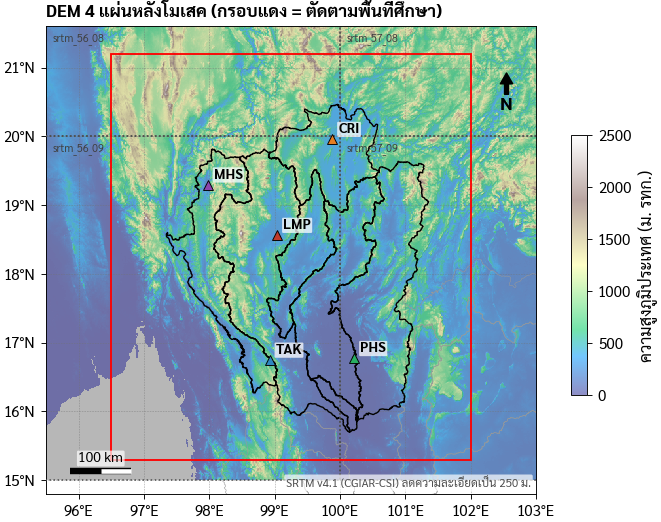

In [3]:
g = cfg["study_area"]["grid"]
bounds = (g["lon_min"], g["lat_min"], g["lon_max"], g["lat_max"])
z, tr, prof = dem.mosaic_tiles(tiles, bounds=bounds, out_path=P.rasters / "02_dem_mosaic.tif")
print(f"DEM โมเสค: {z.shape[1]} × {z.shape[0]} พิกเซล, ความสูง {np.nanmin(z):.0f}–{np.nanmax(z):.0f} ม.")
fig = pl.figure("double", 120)
ax = fig.add_axes([0.05, 0.06, 0.62, 0.9])
from matplotlib.patches import Rectangle
for r in rows:
    ax.add_patch(Rectangle((r["left"], r["bottom"]), r["right"] - r["left"], r["top"] - r["bottom"], fill=False, ec="0.3", lw=1, ls=":", zorder=9))
    ax.text(max(r["left"], 95.5) + 0.1, min(r["top"], 21.6) - 0.1, r["tile"][:10], fontsize=7, va="top", zorder=9,
            color="0.25", clip_on=True)
zf, trf, _ = dem.mosaic_tiles(tiles, res=0.01)          # ทั้ง 4 แผ่น (หยาบลงเพื่อแสดงผล)
mp.hillshade(ax, zf, dem.extent(zf, trf), alpha=0.6, dx_m=1100)
im = ax.imshow(zf, extent=dem.extent(zf, trf), cmap="terrain", vmin=0, vmax=2500, alpha=0.55, zorder=1)
mp.basemap(ax, [95.5, 103, 14.8, 21.6], radars=True, scale_km=100, title="DEM 4 แผ่นหลังโมเสค (กรอบแดง = ตัดตามพื้นที่ศึกษา)")
ax.add_patch(Rectangle((bounds[0], bounds[1]), bounds[2] - bounds[0], bounds[3] - bounds[1], fill=False, ec="red", lw=1.2, zorder=10))
cax = fig.add_axes([0.70, 0.25, 0.02, 0.5]); fig.colorbar(im, cax=cax).set_label(pl.L("elev_m"))
mp.source_note(ax, "SRTM v4.1 (CGIAR-CSI) ลดความละเอียดเป็น 250 ม.")
pl.save(fig, "02_dem_mosaic"); plt.show()
terrain = dem.interpolator(z, tr)      # ฟังก์ชัน f(lat, lon) → ความสูงภูมิประเทศ

**ข้อควรรู้เรื่อง DEM:** (1) DEM ทุกแผ่นต้องมี CRS เดียวกันก่อนโมเสค (2) การลดความละเอียดใช้ค่าเฉลี่ย (`average`) เพื่อไม่ให้ยอดเขาเด่นเกินจริง
(3) ค่าไม่มีข้อมูล (−32768) ต้องแปลงเป็น NaN (4) ความละเอียด 250 ม. เพียงพอสำหรับคำนวณการบังเพราะลำคลื่นกว้างหลายร้อยเมตรขึ้นไป

## 3. ความสูงของลำคลื่นตามระยะ

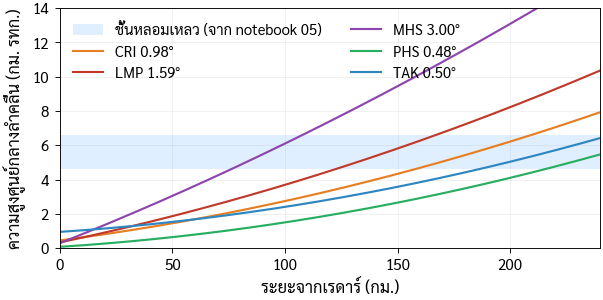

In [4]:
sites = mp.radar_sites()
lowest = {r: float(s.split(";")[0]) for r, s in sites.elevations.items()}
rr = np.linspace(0, 240e3, 481)
fig, ax = pl.subplots(width="one_half", height_mm=70)
ax.axhspan(4.6, 6.6, color="#cce5ff", alpha=0.6, lw=0, label="ชั้นหลอมเหลว (จาก notebook 05)")
for r, el in lowest.items():
    h = geo.beam_height(rr, el, sites.loc[r, "alt_m"]) / 1e3
    ax.plot(rr / 1e3, h, color=mp.RADAR_COLORS[r], lw=1.4, label=f"{r} {el:.2f}°")
ax.set_xlabel(pl.L("range_km")); ax.set_ylabel("ความสูงศูนย์กลางลำคลื่น (กม. รทก.)")
ax.set_xlim(0, 240); ax.set_ylim(0, 14); ax.grid(alpha=0.3, lw=0.4); ax.legend(ncol=2, loc="upper left")
pl.save(fig, "02_beam_height_vs_range"); plt.show()

**แปลผล:** MHS (3°) ทะลุชั้นหลอมเหลวที่ราว 80 กม. จึงวัดฝนได้เฉพาะระยะใกล้ ส่วน PHS (0.48°) และ TAK (0.5°) อยู่ใต้ชั้นหลอมเหลวได้ไกลกว่า 200 กม.
แต่ TAK ตั้งบนดอยมูเซอ (943 ม.) ลำคลื่นต่ำจึงมีโอกาสชนภูเขารอบ ๆ มาก

## 4. ภาพตัดขวาง: ลำคลื่น LMP มุ่งสู่ดอยอินทนนท์และดอยเชียงดาว
ดอยอินทนนท์ (2,565 ม.) อยู่ทางตะวันตกของ LMP ส่วนดอยหลวงเชียงดาว (2,175 ม.) อยู่ในพื้นที่ต้นน้ำปิงทางเหนือ

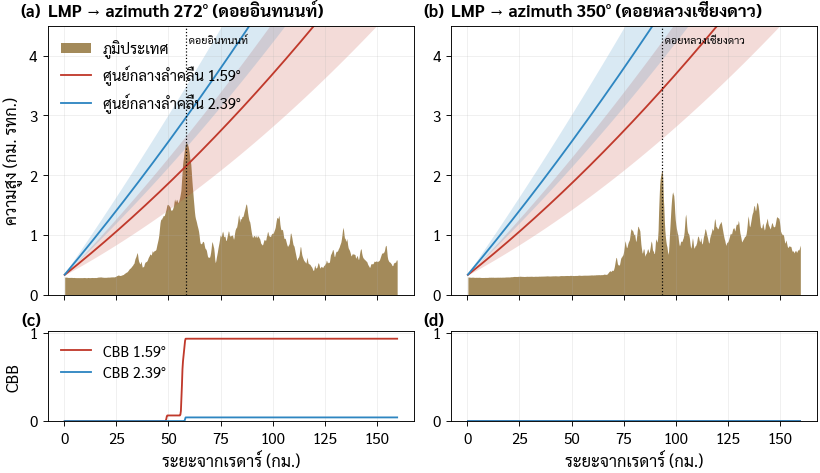

In [5]:
lmp = sites.loc["LMP"]
targets = {"ดอยอินทนนท์": (98.487, 18.588), "ดอยหลวงเชียงดาว": (98.892, 19.398)}
r = np.arange(250, 160e3, 250.0)
fig, axs = pl.subplots(2, 2, width="double", height_mm=110, sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
profiles = {}
for col, (name, (tlon, tlat)) in enumerate(targets.items()):
    az, _, dist = geo.GEOD.inv(lmp.lon, lmp.lat, tlon, tlat); az %= 360
    lon_r, lat_r = geo.polar_lonlat(lmp.lon, lmp.lat, [az], r, 1.59)
    ter = terrain(lat_r[0], lon_r[0]); profiles[name] = (az, ter)
    ax = axs[0, col]
    ax.fill_between(r / 1e3, 0, ter / 1e3, color="#8c6d31", alpha=0.8, lw=0, label="ภูมิประเทศ")
    for el, c in [(1.59, "#c0392b"), (2.39, "#2e86c1")]:
        h = geo.beam_height(r, el, lmp.alt_m) / 1e3; w = geo.beam_radius(r, 1.0) / 1e3
        ax.plot(r / 1e3, h, color=c, lw=1.2, label=f"ศูนย์กลางลำคลื่น {el}°")
        ax.fill_between(r / 1e3, h - w, h + w, color=c, alpha=0.18, lw=0)
        axs[1, col].plot(r / 1e3, geo.cumulative_blockage(geo.partial_blockage(ter, h * 1e3, w * 1e3)), color=c, lw=1.2, label=f"CBB {el}°")
    ax.axvline(dist / 1e3, color="k", ls=":", lw=0.8); ax.text(dist / 1e3, 4.2, " " + name, fontsize=7)
    ax.set_ylim(0, 4.5); ax.set_title(f"LMP → azimuth {az:.0f}° ({name})", loc="left", fontweight="bold")
    axs[1, col].set_ylim(0, 1.02); axs[1, col].set_xlabel(pl.L("range_km"))
axs[0, 0].set_ylabel("ความสูง (กม. รทก.)"); axs[1, 0].set_ylabel("CBB")
axs[0, 0].legend(loc="upper left"); axs[1, 0].legend(loc="upper left")
for a in axs.ravel(): a.grid(alpha=0.3, lw=0.4)
pl.panel_labels(axs); pl.save(fig, "02_beam_cross_sections"); plt.show()

**แปลผล:** ทางตะวันตก ลำคลื่น 1.59° ชนดอยอินทนนท์จนถูกบังเกือบทั้งหมด (CBB → 1) ทุกอย่างหลังภูเขาจึงมองไม่เห็นด้วยมุมนี้
ส่วนมุม 2.39° ลอดผ่านได้ ทางเหนือ ลำคลื่นผ่านเหนือดอยเชียงดาวได้ แต่ฐานลำคลื่นสูงจากพื้นหุบเขา 2–3 กม.
นี่คือ **ปัญหาสองทาง** ของเรดาร์ในพื้นที่ภูเขา: มุมต่ำถูกบัง มุมสูงลอยเหนือฝนชั้นล่าง → ต้องเลือกมุมยกแบบปรับตามพื้นที่ (hybrid scan, notebook 04)

## 5. แผนที่ CBB และ RQI ของ LMP (มุมต่ำสุด)

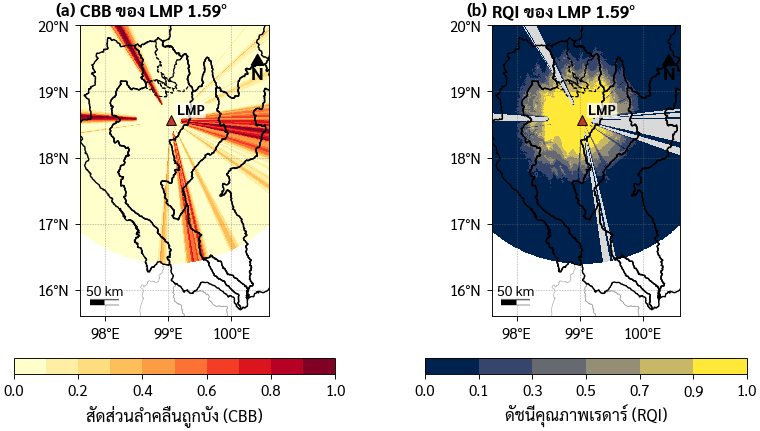

In [6]:
scans = io.list_scans(P.radar / "20241003_00UTC")
first = scans.groupby("radar").path.first()
G = {}
for rad, path in first.items():
    rd = io.read_radar(path)
    G[rad] = mosaic.radar_geometry(rd, terrain, beamwidth=float(sites.loc[rad, "beamwidth_deg"]))
g0 = G["LMP"][0]
q0 = RQ.rqi(g0["cbb"], g0["hagl"])
E = cfg["study_area"]["map_extent"]["ping_wang"]
fig, axs = pl.subplots(1, 2, width="double", height_mm=100)
lon_l, lat_l = g0["lon"], g0["lat"]
cm_c = plt.get_cmap("YlOrRd", 10)
im1 = axs[0].pcolormesh(lon_l, lat_l, g0["cbb"], cmap=cm_c, vmin=0, vmax=1, shading="nearest", rasterized=True)
mp.basemap(axs[0], E, radars=["LMP"], subbasins=cfg["study_area"]["ping_headwater_subbasins"], title="CBB ของ LMP 1.59°")
cm_q, nm_q = pl.rqi_cmap()
im2 = axs[1].pcolormesh(lon_l, lat_l, np.where(q0 > 0, q0, np.nan), cmap=cm_q, norm=nm_q, shading="nearest", rasterized=True)
mp.basemap(axs[1], E, radars=["LMP"], subbasins=cfg["study_area"]["ping_headwater_subbasins"], title="RQI ของ LMP 1.59°")
fig.colorbar(im1, ax=axs[0], orientation="horizontal", shrink=0.8).set_label(pl.L("cbb"))
fig.colorbar(im2, ax=axs[1], orientation="horizontal", shrink=0.8).set_label(pl.L("rqi"))
pl.panel_labels(axs); pl.save(fig, "02_lmp_cbb_rqi"); plt.show()

## 6. RQI ของทั้งเครือข่าย: เรดาร์ใดดีที่สุดในแต่ละพิกเซล
แปลงค่าแบบ polar ของแต่ละเรดาร์ลงกริด 0.01° (`PolarToGrid`) แล้วเลือกค่า RQI สูงสุด

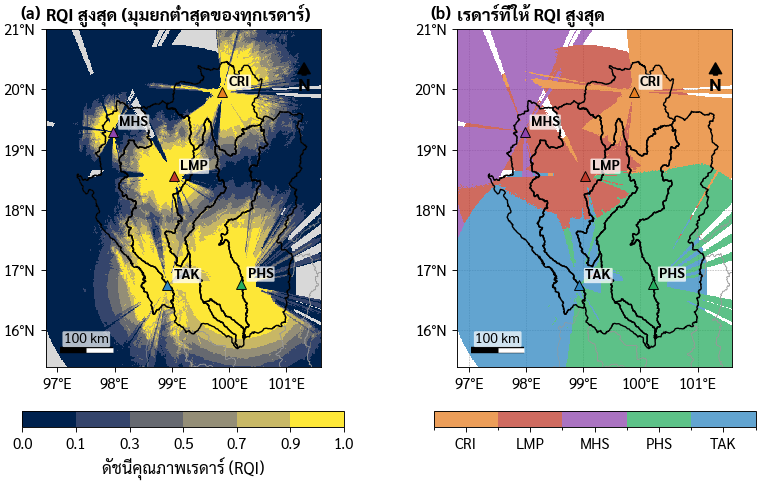

In [7]:
glon, glat = mosaic.make_grid(g["lon_min"], g["lon_max"], g["lat_min"], g["lat_max"], g["res_deg"])
radars = sorted(G)
Q = np.zeros((len(radars), len(glat), len(glon)))
H = np.full_like(Q, np.nan)
for i, rad in enumerate(radars):
    gg = G[rad][0]
    m = mosaic.PolarToGrid(gg["lon0"], gg["lat0"], mosaic.AZ_GRID, gg["r"], glon, glat)
    Q[i] = m(RQ.rqi(gg["cbb"], gg["hagl"]), 0.0)
    H[i] = m(gg["hagl"])
best_q = Q.max(0)
best_r = np.where(best_q > 0, Q.argmax(0), -1)
best_h = np.take_along_axis(H, np.clip(best_r, 0, None)[None], 0)[0]
from matplotlib.colors import ListedColormap, BoundaryNorm
fig, axs = pl.subplots(1, 2, width="double", height_mm=112)
E2 = cfg["study_area"]["map_extent"]["north"]
im = mp.show_grid(axs[0], np.where(best_q > 0, best_q, np.nan), glon, glat, *pl.rqi_cmap())
mp.basemap(axs[0], E2, title="RQI สูงสุด (มุมยกต่ำสุดของทุกเรดาร์)", scale_km=100)
fig.colorbar(im, ax=axs[0], orientation="horizontal", shrink=0.8).set_label(pl.L("rqi"))
cmr = ListedColormap([mp.RADAR_COLORS[r] for r in radars])
im2 = mp.show_grid(axs[1], np.where(best_r >= 0, best_r, np.nan), glon, glat, cmr, BoundaryNorm(np.arange(-0.5, len(radars)), len(radars)), alpha=0.75)
mp.basemap(axs[1], E2, title="เรดาร์ที่ให้ RQI สูงสุด", scale_km=100)
cb = fig.colorbar(im2, ax=axs[1], orientation="horizontal", shrink=0.8, ticks=range(len(radars))); cb.ax.set_xticklabels(radars)
pl.panel_labels(axs); pl.save(fig, "02_network_rqi_best_radar"); plt.show()
mosaic.to_geotiff(P.rasters / "02_rqi_lowest_sweep.tif", best_q, glon, glat)

## 7. สถิติรายลุ่มน้ำ (zonal statistics)
แปลงขอบลุ่มน้ำเป็น raster บนกริดเดียวกับ RQI (`rasterio.features.rasterize`) แล้วสรุปค่า

In [8]:
from rasterio.features import rasterize
from rasterio.transform import from_origin
mb, sb, _ = mp.boundaries()
transform = from_origin(glon[0] - 0.005, glat[0] + 0.005, 0.01, 0.01)
def zone_stats(gdf, key, names):
    rows = []
    for _, rw in gdf.iterrows():
        msk = rasterize([(rw.geometry, 1)], out_shape=best_q.shape, transform=transform, fill=0).astype(bool)
        q = best_q[msk]; h = best_h[msk]
        rows.append({key: names.get(rw[key], rw[key]), "พื้นที่ (km²)": round(msk.sum() * 1.1 * 1.05),
                     "RQI เฉลี่ย": q.mean(), "% RQI ≥ 0.5": 100 * np.mean(q >= 0.5), "% ไม่มีข้อมูล": 100 * np.mean(q == 0),
                     "ความสูงลำคลื่นเหนือพื้น มัธยฐาน (กม.)": np.nanmedian(h) / 1e3})
    return pd.DataFrame(rows).round(2)
basins = cfg["study_area"]["basins_of_interest"]
tab = zone_stats(mb[mb.MB_CODE.isin(basins)], "MB_CODE", basins)
hw = sb[sb.SB_CODE.isin(cfg["study_area"]["ping_headwater_subbasins"])].dissolve().assign(MB_CODE="Ping headwater")
tab = pd.concat([tab, zone_stats(hw, "MB_CODE", {})], ignore_index=True)
tab.to_csv(P.tables / "02_rqi_by_basin.csv", index=False)
tab

,MB_CODE,พื้นที่ (km²),RQI เฉลี่ย,% RQI ≥ 0.5,% ไม่มีข้อมูล,ความสูงลำคลื่นเหนือพื้น มัธยฐาน (กม.)
0,Salawin,18867,0.38,35.40,3.02,2.91
1,North Khong,17353,0.64,66.54,0.00,1.27
2,Ping,34003,0.73,75.62,0.53,1.49
3,Wang,10635,0.54,56.15,0.00,2.03
4,Yom,23641,0.67,65.73,0.00,1.61
5,Nan,34272,0.48,45.39,0.12,1.70
6,Ping headwater,5813,0.41,42.00,2.98,2.40


**แปลผล (อภิปราย):** ลุ่มน้ำวังและยมได้ RQI สูงเพราะอยู่ใกล้ LMP/PHS ส่วนสาละวินและต้นน้ำปิงมีพื้นที่ที่ไม่มีข้อมูลหรือ RQI ต่ำ
เพราะภูเขาบังและลำคลื่นสูง — ต้นน้ำปิงเป็นแหล่งกำเนิดน้ำท่วมเชียงใหม่ แต่กลับเป็นพื้นที่ที่เรดาร์ "มองเห็น" ได้แย่ที่สุดแห่งหนึ่ง

---
## ✏️ แบบฝึกหัด

### แบบฝึกหัด 1 · 🟢 ป.ตรี

คำนวณความสูงศูนย์กลางลำคลื่นที่ระยะ **100 กม.** สำหรับมุมยก 0.5° และ 1.59° (ฐานเรดาร์ที่ระดับน้ำทะเล) ต่างกันกี่กิโลเมตร

In [9]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
h05 = None; h159 = None   # km

In [10]:
#@title 🔑 เฉลยข้อ 1 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
h05 = geo.beam_height(100e3, 0.5) / 1e3
h159 = geo.beam_height(100e3, 1.59) / 1e3
print(f"0.5° → {h05:.2f} km, 1.59° → {h159:.2f} km, ต่างกัน {h159 - h05:.2f} km")
assert abs(h05 - 1.46) < 0.05 and abs(h159 - 3.36) < 0.05

0.5° → 1.46 km, 1.59° → 3.36 km, ต่างกัน 1.90 km


### แบบฝึกหัด 2 · 🟢 ป.ตรี

ลำคลื่นมุมต่ำสุดของ LMP (1.59°, ฐาน 328 ม.) ขึ้นถึงความสูง **4.8 กม.** (ชั้นหลอมเหลวโดยประมาณ) ที่ระยะเท่าใด ใช้ `geo.range_for_height`

In [11]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
r48 = None   # km

In [12]:
#@title 🔑 เฉลยข้อ 2 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
r48 = geo.range_for_height(4800, 1.59, 328) / 1e3
print(f"LMP 1.59° ถึง 4.8 km ที่ระยะ {r48:.0f} km → ไกลกว่านี้วัดในชั้นหลอมเหลว/หิมะ")
assert 120 < r48 < 135

LMP 1.59° ถึง 4.8 km ที่ระยะ 127 km → ไกลกว่านี้วัดในชั้นหลอมเหลว/หิมะ


### แบบฝึกหัด 3 · 🟢 ป.ตรี

จากตาราง `tab` ลุ่มน้ำใดมี **RQI เฉลี่ยต่ำที่สุด** และ **ร้อยละพื้นที่ไม่มีข้อมูลสูงสุด** อธิบายสาเหตุด้วยแผนที่ในข้อ 6

In [13]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
worst = None

In [14]:
#@title 🔑 เฉลยข้อ 3 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
worst = tab.sort_values("RQI เฉลี่ย").iloc[0]
print("RQI ต่ำสุด:", worst.MB_CODE, round(worst["RQI เฉลี่ย"], 2))
print("ไม่มีข้อมูลมากสุด:", tab.loc[tab["% ไม่มีข้อมูล"].idxmax(), "MB_CODE"])
print("สาเหตุ: อยู่ไกลเรดาร์ (ลำคลื่นสูง) และมีเทือกเขาสูงบังลำคลื่นมุมต่ำ")

RQI ต่ำสุด: Salawin 0.38
ไม่มีข้อมูลมากสุด: Salawin
สาเหตุ: อยู่ไกลเรดาร์ (ลำคลื่นสูง) และมีเทือกเขาสูงบังลำคลื่นมุมต่ำ


### แบบฝึกหัด 4 · 🔵 ป.โท / ส่วนขยาย

บรรยากาศช่วงกลางคืนอาจมี **การหักเหมากผิดปกติ (super-refraction)** แทนด้วย $k_e = 2$
คำนวณ CBB ตามแนวดอยอินทนนท์ (มุม 1.59°) ใหม่ด้วย `geo.beam_height(..., ke=2)` แล้วเปรียบเทียบกับ $k_e = 4/3$
และอธิบายว่าทำไม anomalous propagation (AP) จึงทำให้เกิด clutter ที่เห็นใน notebook 01

In [15]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
cbb_ke2 = None

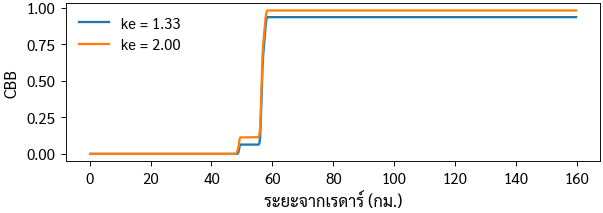

ke ใหญ่ → ลำคลื่นโค้งลงหาพื้นมากขึ้น ถูกบังมากขึ้นและกระทบพื้นไกลออกไป = ground clutter แบบ AP


In [16]:
#@title 🔑 เฉลยข้อ 4 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
az, ter = profiles["ดอยอินทนนท์"]
w = geo.beam_radius(r, 1.0)
out = {}
for ke in [4 / 3, 2.0]:
    h = geo.beam_height(r, 1.59, lmp.alt_m, ke=ke)
    out[ke] = geo.cumulative_blockage(geo.partial_blockage(ter, h, w))
cbb_ke2 = out[2.0]
fig, ax = pl.subplots(width="one_half", height_mm=50)
for ke, v in out.items():
    ax.plot(r / 1e3, v, label=f"ke = {ke:.2f}")
ax.set_xlabel(pl.L("range_km")); ax.set_ylabel("CBB"); ax.legend(); plt.show()
print("ke ใหญ่ → ลำคลื่นโค้งลงหาพื้นมากขึ้น ถูกบังมากขึ้นและกระทบพื้นไกลออกไป = ground clutter แบบ AP")
assert np.argmax(cbb_ke2 > 0.5) <= np.argmax(out[4 / 3] > 0.5)

### แบบฝึกหัด 5 · 🔵 ป.โท / ส่วนขยาย

แนวคิด **hybrid scan**: คำนวณร้อยละของ bin ใน sweep แรกของ LMP ที่ CBB ≥ 0.5 แล้วดูว่าถ้าเลื่อนไปใช้ sweep ที่สอง (2.39°) จะเหลือกี่เปอร์เซ็นต์ และความสูงลำคลื่นเหนือพื้นเพิ่มขึ้นเท่าใด

In [17]:
# ✏️ เขียนคำตอบของคุณในเซลล์นี้
blocked0 = None; blocked1 = None

In [18]:
#@title 🔑 เฉลยข้อ 5 — ลองทำเองก่อน แล้วดับเบิลคลิกเพื่อดูโค้ด { display-mode: "form" }
c0, c1 = G["LMP"][0]["cbb"], G["LMP"][1]["cbb"]
blocked0, blocked1 = 100 * np.mean(c0 >= 0.5), 100 * np.mean(c1 >= 0.5)
sel = c0 >= 0.5
dh = np.nanmedian((G["LMP"][1]["hagl"] - G["LMP"][0]["hagl"])[sel]) / 1e3
print(f"ถูกบัง ≥ 50%: sweep 1.59° = {blocked0:.1f}%, sweep 2.39° = {blocked1:.1f}%")
print(f"แต่ลำคลื่นสูงขึ้น (มัธยฐาน) {dh:.2f} km ในบริเวณที่ย้าย → แลกคุณภาพการบังกับความสูง")

ถูกบัง ≥ 50%: sweep 1.59° = 9.2%, sweep 2.39° = 0.0%
แต่ลำคลื่นสูงขึ้น (มัธยฐาน) 1.85 km ในบริเวณที่ย้าย → แลกคุณภาพการบังกับความสูง


---
## 💡 คำถามชวนคิดและต่อยอด
- DEM 30 ม. (Copernicus GLO-30) กับ 250 ม. จะให้ CBB ต่างกันมากหรือไม่ ลองดาวน์โหลดและเปรียบเทียบ (เขียนลงใน `config/`)
- นอกจากภูเขา สิ่งปลูกสร้าง/ต้นไม้ใกล้เรดาร์ก็บังลำคลื่นได้ จะตรวจจากข้อมูลเรดาร์ระยะยาว (สะสม Z หลายเดือน) ได้อย่างไร
- RQI ควรรวมปัจจัยอื่นอีกไหม เช่น ระยะทาง (ขนาดปริมาตรสุ่มตัวอย่าง) คุณภาพ ΦDP ความถี่ในการสแกน
- 🔵 เปรียบเทียบสูตร RQI ของ MRMS (สหรัฐฯ), JMA (ญี่ปุ่น) และ MeteoSwiss แล้วออกแบบสูตรสำหรับเครือข่ายไทย

## 📚 อ้างอิง
- Bech, J. et al. (2003). The sensitivity of single polarization weather radar beam blockage correction to variability in the vertical refractivity gradient. *J. Atmos. Oceanic Technol.* 20:845–855.
- Zhang, J. et al. (2012). Radar Quality Index (RQI) — a combined measure of beam blockage and VPR effects in a national network. *IAHS Publ.* 351:388–393.
- Fulton, R.A. et al. (1998). The WSR-88D rainfall algorithm. *Weather and Forecasting* 13:377–395.
- Germann, U. et al. (2022). Weather radar in complex orography. *Remote Sensing* 14:503. doi:10.3390/rs14030503
- Jarvis, A. et al. (2008). Hole-filled SRTM for the globe, Version 4. CGIAR-CSI SRTM 90m Database.

In [19]:
#@title 💾 บันทึกผลลัพธ์ขึ้น GitHub (fork ของคุณเอง) { display-mode: "form" }
#@markdown ใส่รหัสนิสิต แล้วรันเซลล์นี้ (ต้องตั้ง Colab Secrets `GITHUB_USER` และ `GITHUB_TOKEN` ก่อน — ดูขั้นตอนใน notebook 00)
STUDENT_ID = ""  #@param {type:"string"}
if STUDENT_ID:
    colab.save_to_fork(STUDENT_ID, message="NB02: results")
else:
    print("ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)")

ยังไม่ได้ใส่รหัสนิสิต — ข้ามการบันทึก (ผลยังอยู่ในโฟลเดอร์ outputs/ ของ Colab)
